# Wightman functions

*Numerical mode sum (Abel-regularised) vs analytic closed form; short-distance structure.*

All computations call `desitter_qft`; see the matching `docs/` file for derivations.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from IPython.display import Image, display
from desitter_qft.plotting import apply_style; apply_style()
FIG = os.path.abspath(os.path.join('..', 'figures'))

In [2]:
from desitter_qft.two_point import *
for nu in (0.5, 1.0, 1.3, 0.8j):
    for r in (0.3, 2.0):
        a = wightman_mode_sum(-1.0, r, nu); b = wightman_closed_form_equal_time(-1.0, r, nu)
        print(f'nu={nu}, r={r}: mode sum {a:.12e}  closed form {b:.12e}  rel diff {abs(a/b-1):.1e}')

nu=0.5, r=0.3: mode sum 2.814477323398e-01  closed form 2.814477323398e-01  rel diff 1.6e-15
nu=0.5, r=2.0: mode sum 6.332573977646e-03  closed form 6.332573977646e-03  rel diff 0.0e+00
nu=1.0, r=0.3: mode sum 3.049930897397e-01  closed form 3.049930897397e-01  rel diff 1.4e-13
nu=1.0, r=2.0: mode sum 1.492077591486e-02  closed form 1.492077591487e-02  rel diff 8.6e-14
nu=1.3, r=0.3: mode sum 3.554512497458e-01  closed form 3.554512497458e-01  rel diff 9.3e-15
nu=1.3, r=2.0: mode sum 4.873870115796e-02  closed form 4.873870115796e-02  rel diff 8.7e-15


nu=0.8j, r=0.3: mode sum 2.631296516445e-01  closed form 2.631296516447e-01  rel diff 8.7e-13


nu=0.8j, r=2.0: mode sum 2.849763261562e-03  closed form 2.849763261826e-03  rel diff 9.3e-11


nu=1.0: A,B,C = 0.00633, -0.00475, 0.00525; residual at u=1e-6: 4.16e-08
nu=1.4: A,B,C = 0.00633, -0.01083, 0.10165; residual at u=1e-6: 2.25e-08


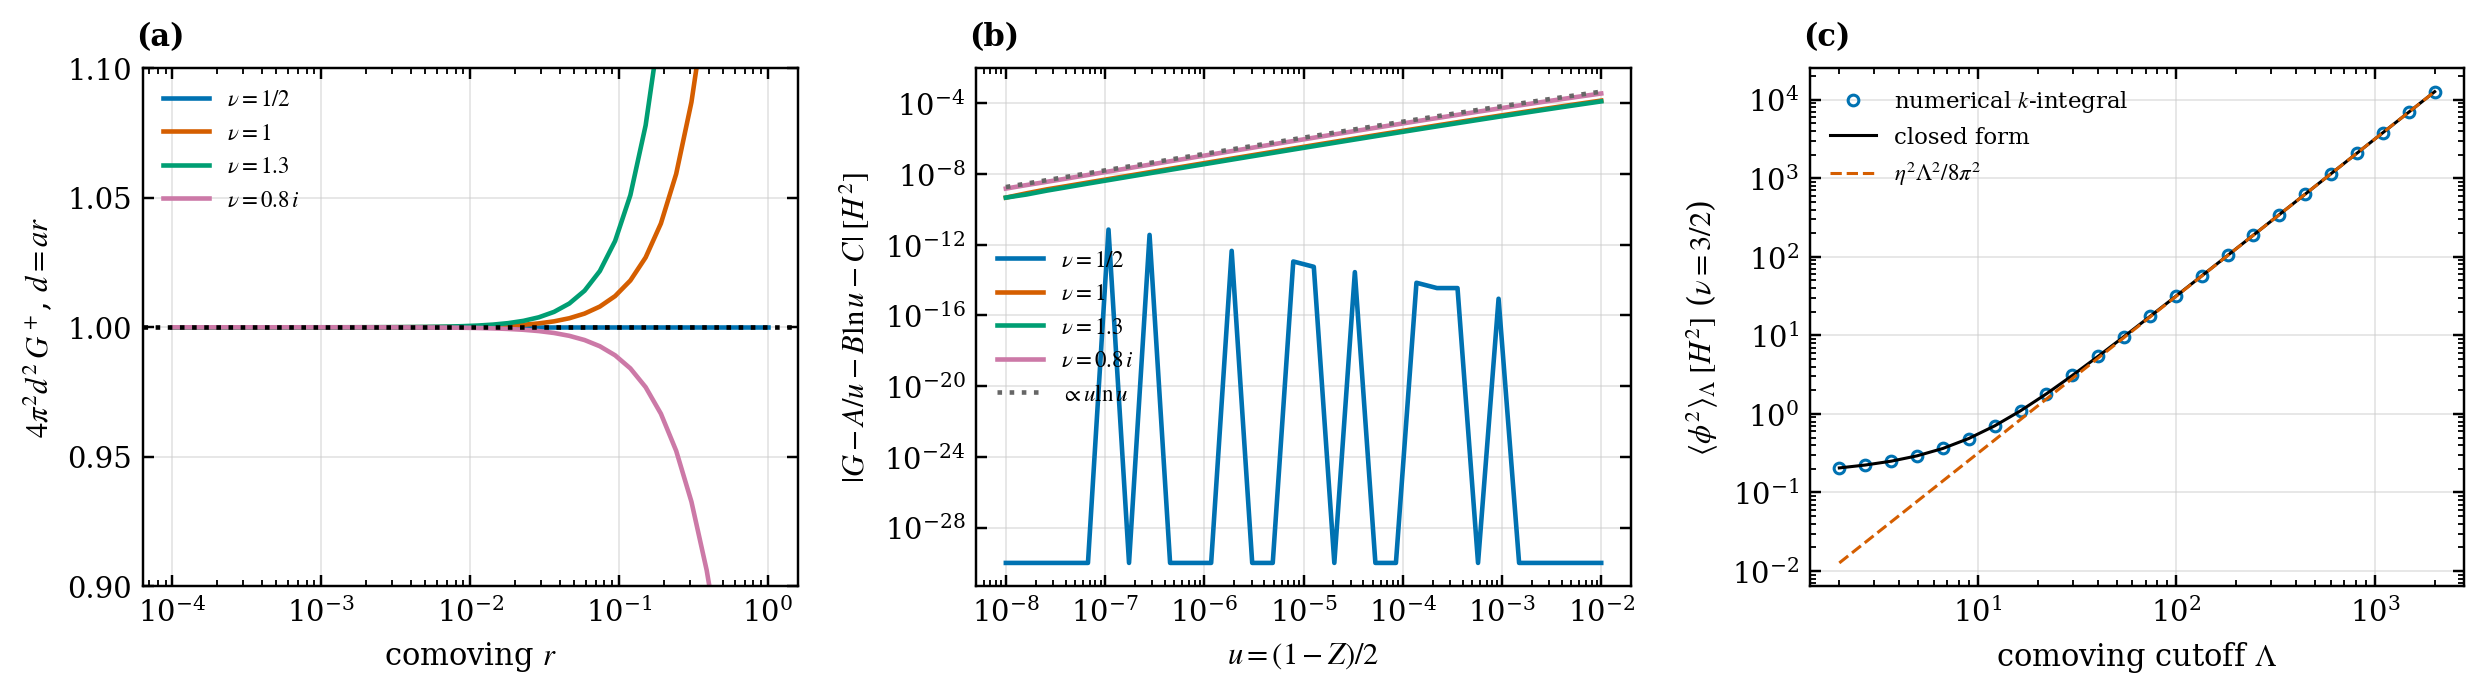

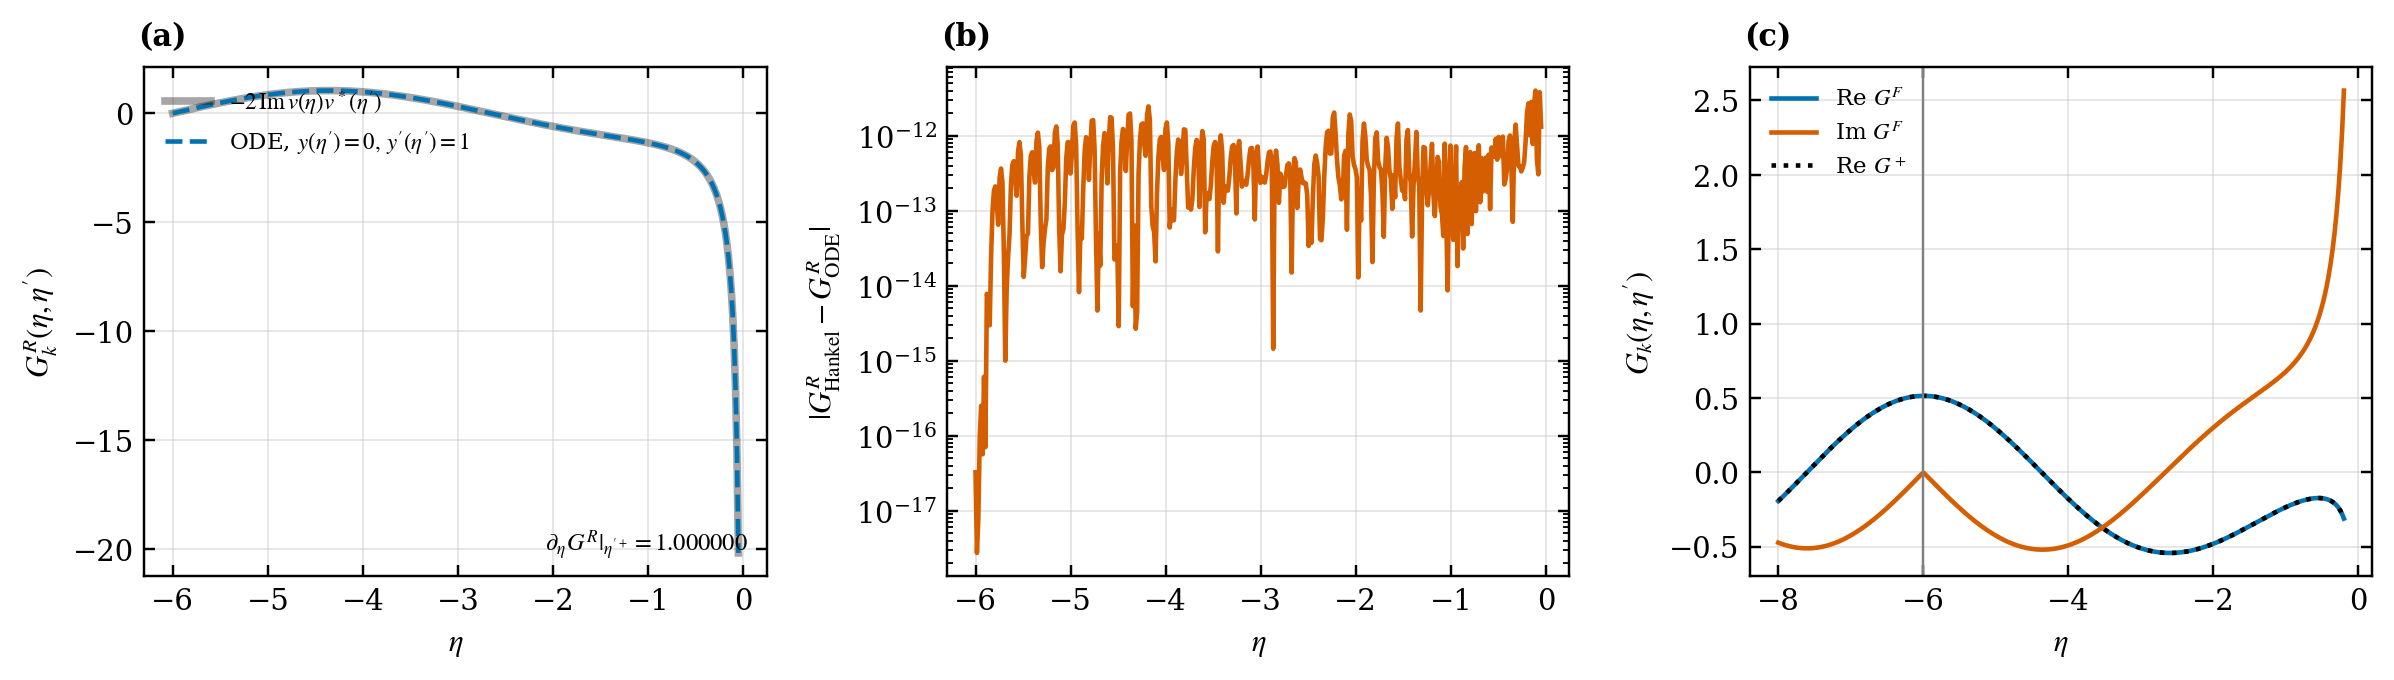

In [3]:
for nu in (1.0, 1.4):
    A, B, C = short_distance_coefficients(nu); u = 1e-6
    print(f'nu={nu}: A,B,C = {A:.5f}, {B:.5f}, {C:.5f}; residual at u=1e-6: {float(wightman_closed_form_u(u, nu)) - (A/u + B*np.log(u) + C):.2e}')
display(Image(os.path.join(FIG, 'fig06_ultraviolet_structure.png'))); display(Image(os.path.join(FIG, 'fig08_mode_space_propagators.png')))